In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from post_analysis import parse_cv_metrics

In [ ]:
def ceiling_div(n,d):
    return (n+d-1)//d

def backbone(model):
    if "GCN" in model:
        return "GCN"
    elif "GAT" in model:
        return "GAT"
    elif "GIN" in model:
        return "GIN"
    elif "RuleOnly" in model:
        return "RuleOnly"
    else:
        return "Other"

def variation_suffix(model):
    if "_" not in model:
        return "Baseline"
    else:
        suf = model.split("_")[1:]
        suffix = "_".join(suf)
        return suffix
NPG_variant_colors = {
    "base": "#E64B35",               # Red
    "+topo": "#4DBBD5",              # Light Blue
    "+direct_rules": "#00A087",      # Teal
    "+all_rules": "#3C5488",         # Dark Blue
    "+topo+direct_rules": "#F39B7F", # Peach
    "+topo+all_rules": "#8491B4"     # Slate Grey
}
Tab10_variant_colors = {
    "base": "#1f77b4",               # Muted Blue
    "+topo": "#ff7f0e",              # Safety Orange
    "+direct_rules": "#2ca02c",      # Cooked Asparagus Green
    "+all_rules": "#d62728",         # Brick Red
    "+topo+direct_rules": "#9467bd", # Muted Purple
    "+topo+all_rules": "#8c564b"     # Chestnut Brown
}
    
def boxplot_all_backbones_subplots(df, 
                                   metric_name: str, 
                                   dataset: str, 
                                   k: str|int=4,
                                   output_dir=None):
    
    # define palette:Okabe-Ito
    variant_colors = {
        "base": "#E69F00",                # Orange (GNN / RuleOnly base)
        "topo": "#56B4E9",               # Sky Blue
        "direct_rules": "#009E73",       # Bluish Green
        "all_rules": "#F0E442",          # Yellow
        "topo_direct_rules": "#0072B2",  # Blue
        "topo_all_rules": "#D55E00"      # Vermilion
    }
    
    # identify variant type from model string
    def get_variant_type(model_name):
        if "topo_all_rules" in model_name: return "topo_all_rules"
        if "topo_direct_rules" in model_name: return "topo_direct_rules"
        if "all_rules" in model_name: return "all_rules"
        if "direct_rules" in model_name: return "direct_rules"
        if "topo" in model_name: return "topo"
        return "base"
    
    # Sorting order to guarantee identical box order across subplots
    variant_order = {
        "base": 0,
        "topo": 1,
        "direct_rules": 2,
        "all_rules": 3,
        "topo_direct_rules": 4,
        "topo_all_rules": 5
    }

    # Filter and copy to avoid SettingWithCopyWarning
    plot_df = df[
        (df["metric"] == metric_name) & 
        (df["k"] == str(k)) &
        (df['dataset'] == dataset)
    ].copy()
    
    plot_df["backbone"] = plot_df["model"].apply(backbone) # Assuming `backbone` is defined elsewhere
    
    # Create the fixed palette dictionary for all unique models in this subset
    model_palette = {m: variant_colors[get_variant_type(m)] for m in plot_df['model'].unique()}
    
    backbones = sorted(plot_df['backbone'].unique())
    num_subplots = len(backbones)
    
    # Create grid based on number of backbones (assuming ceiling_div is imported)
    fig, axes = plt.subplots(2, ceiling_div(num_subplots, 2), figsize=(16, 12))
    axes = axes.flatten()
    
    for i, bb in enumerate(backbones):
        ax = axes[i]
        bb_df = plot_df[plot_df["backbone"] == bb]
        
        # sort model's variants order
        model_order = sorted(
            bb_df['model'].unique(), 
            key=lambda x: variant_order[get_variant_type(x)]
        )
        
        # 1. Plot the boxes
        sns.boxplot(
            data=bb_df,
            x="model",
            y="score",
            hue="model",
            ax=ax,
            palette=model_palette, # Apply the fixed dictionary
            legend=False,
            order=model_order      # Apply the fixed logical order
        )
        
        # 2. Add data dots
        sns.stripplot(
            data=bb_df,
            x="model",
            y="score",
            color="black",
            alpha=0.5,
            jitter=True,
            size=5,
            ax=ax,
            order=model_order      # Keep dots aligned with boxes
        )
        
        # 3. Calculate and annotate Mean & Std inside boxes
        for idx, m in enumerate(model_order):
            scores = bb_df[bb_df["model"] == m]["score"]
            mean_val = scores.mean()
            std_val = scores.std()
            
            # Place text at the mean coordinate
            ax.text(
                idx, mean_val, 
                f"{mean_val:.3f}\n±{std_val:.3f}", 
                ha='center', va='center', 
                color='black', fontsize=9, fontweight='bold',
                bbox=dict(facecolor='white', alpha=0.75, edgecolor='none', boxstyle='round,pad=0.2')
            )
        
        ax.set_title(f"{bb} Variations", fontsize=16)
        ax.set_xlabel("")
        ax.set_ylabel(metric_name.capitalize(), fontsize=10)
        
        # Rotate x-labels and adjust alignment so they look clean
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
        
    # Remove any empty subplots (if num_subplots is odd)
    for j in range(num_subplots, len(axes)):
        fig.delaxes(axes[j])
        
    fig.suptitle(f"Performance comparison: {metric_name.capitalize()} | {dataset} | k={k}", fontsize=20)
    plt.tight_layout()
    
    # --- SAVE PLOT LOGIC ---
    if output_dir:
        os.makedirs(output_dir, exist_ok=True) 
        filename = f"all_backbones_{dataset}_k{k}_{metric_name}.png"
        filepath = os.path.join(output_dir, filename)
        plt.savefig(filepath, dpi=300, bbox_inches='tight')
        print(f"Saved plot to: {filepath}")
        
    plt.show()

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of tic

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_backbones_ANMerge_k4_accuracy.png


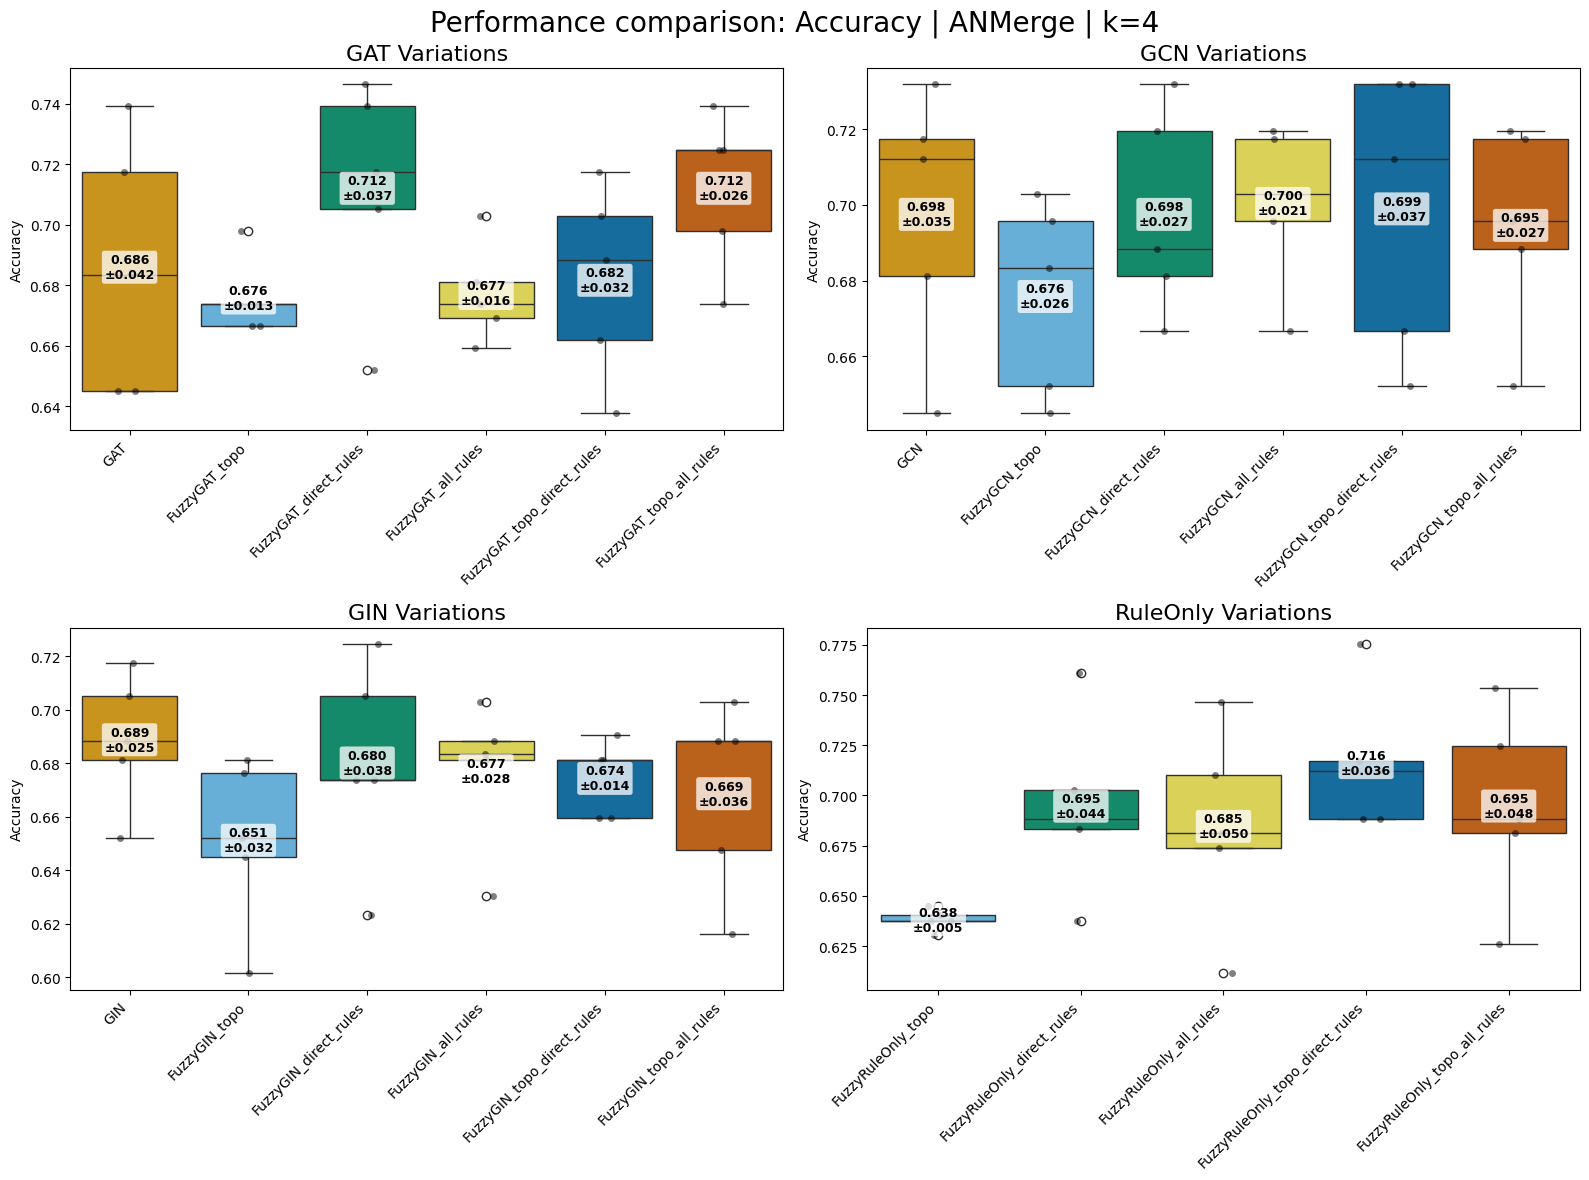

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of tic

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_backbones_ANMerge_k4_balanced_accuracy.png


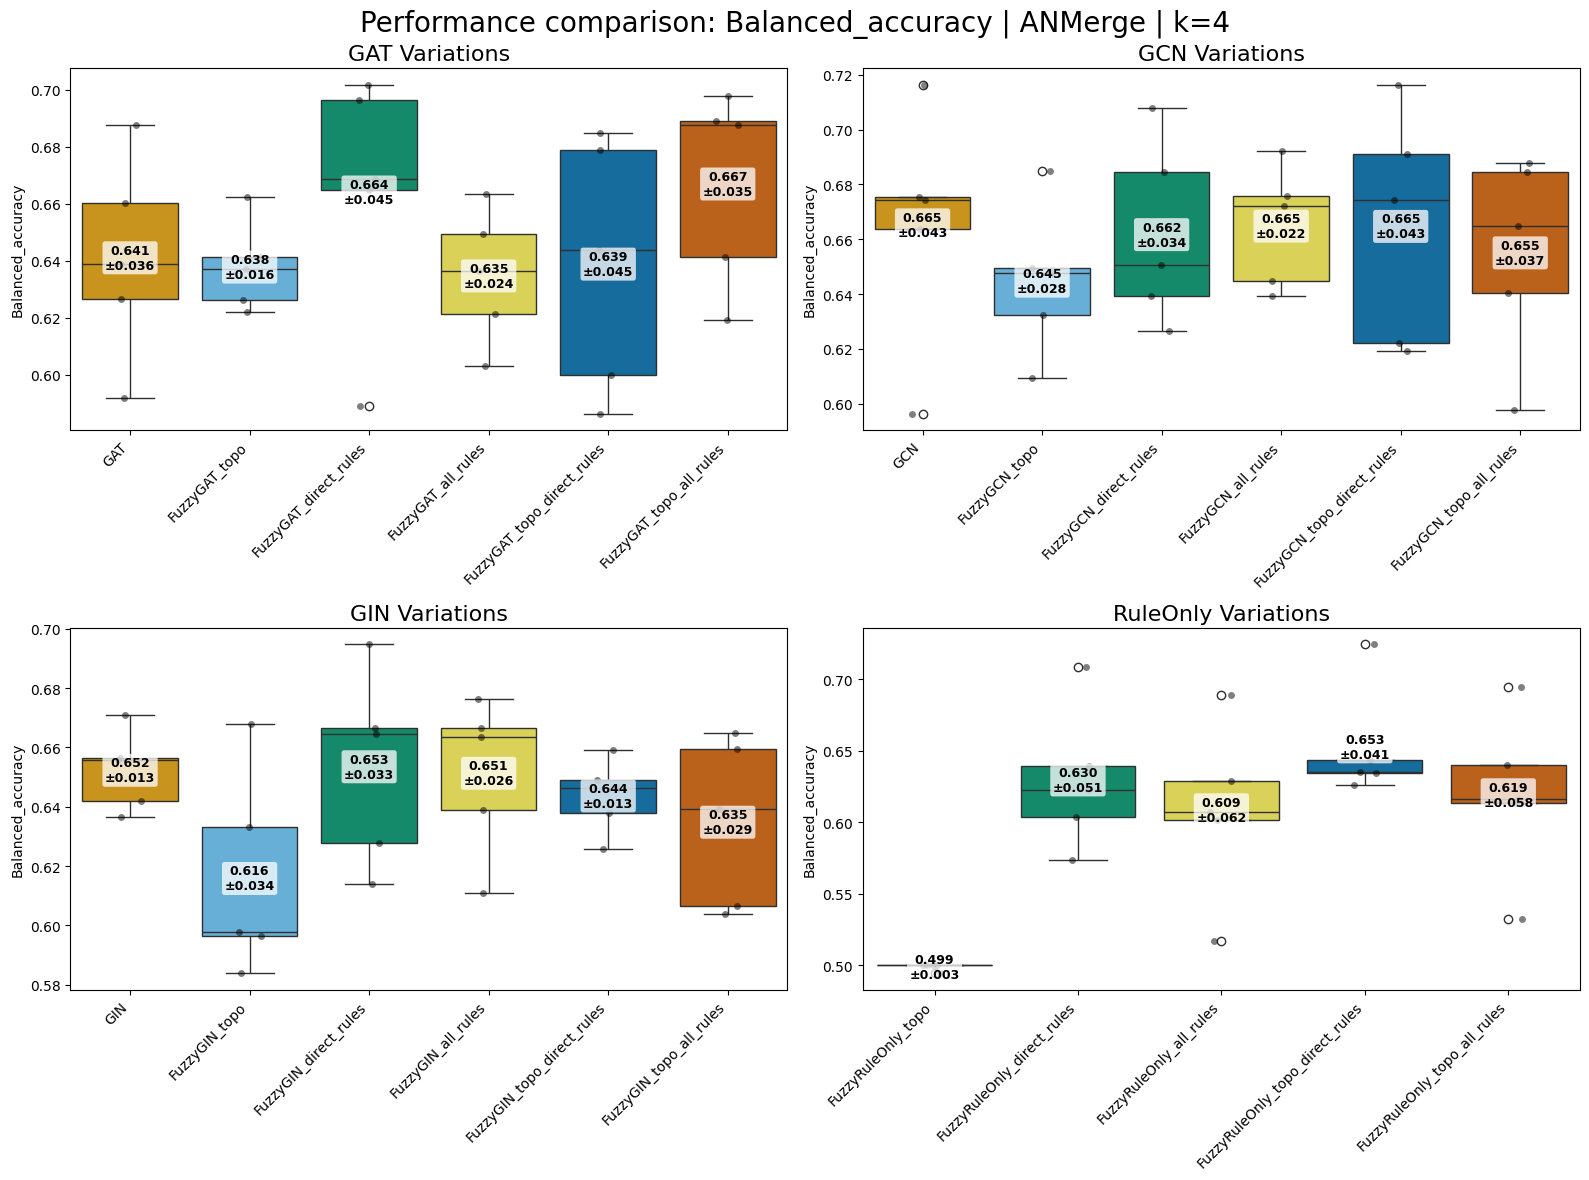

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of tic

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_backbones_ANMerge_k4_f1.png


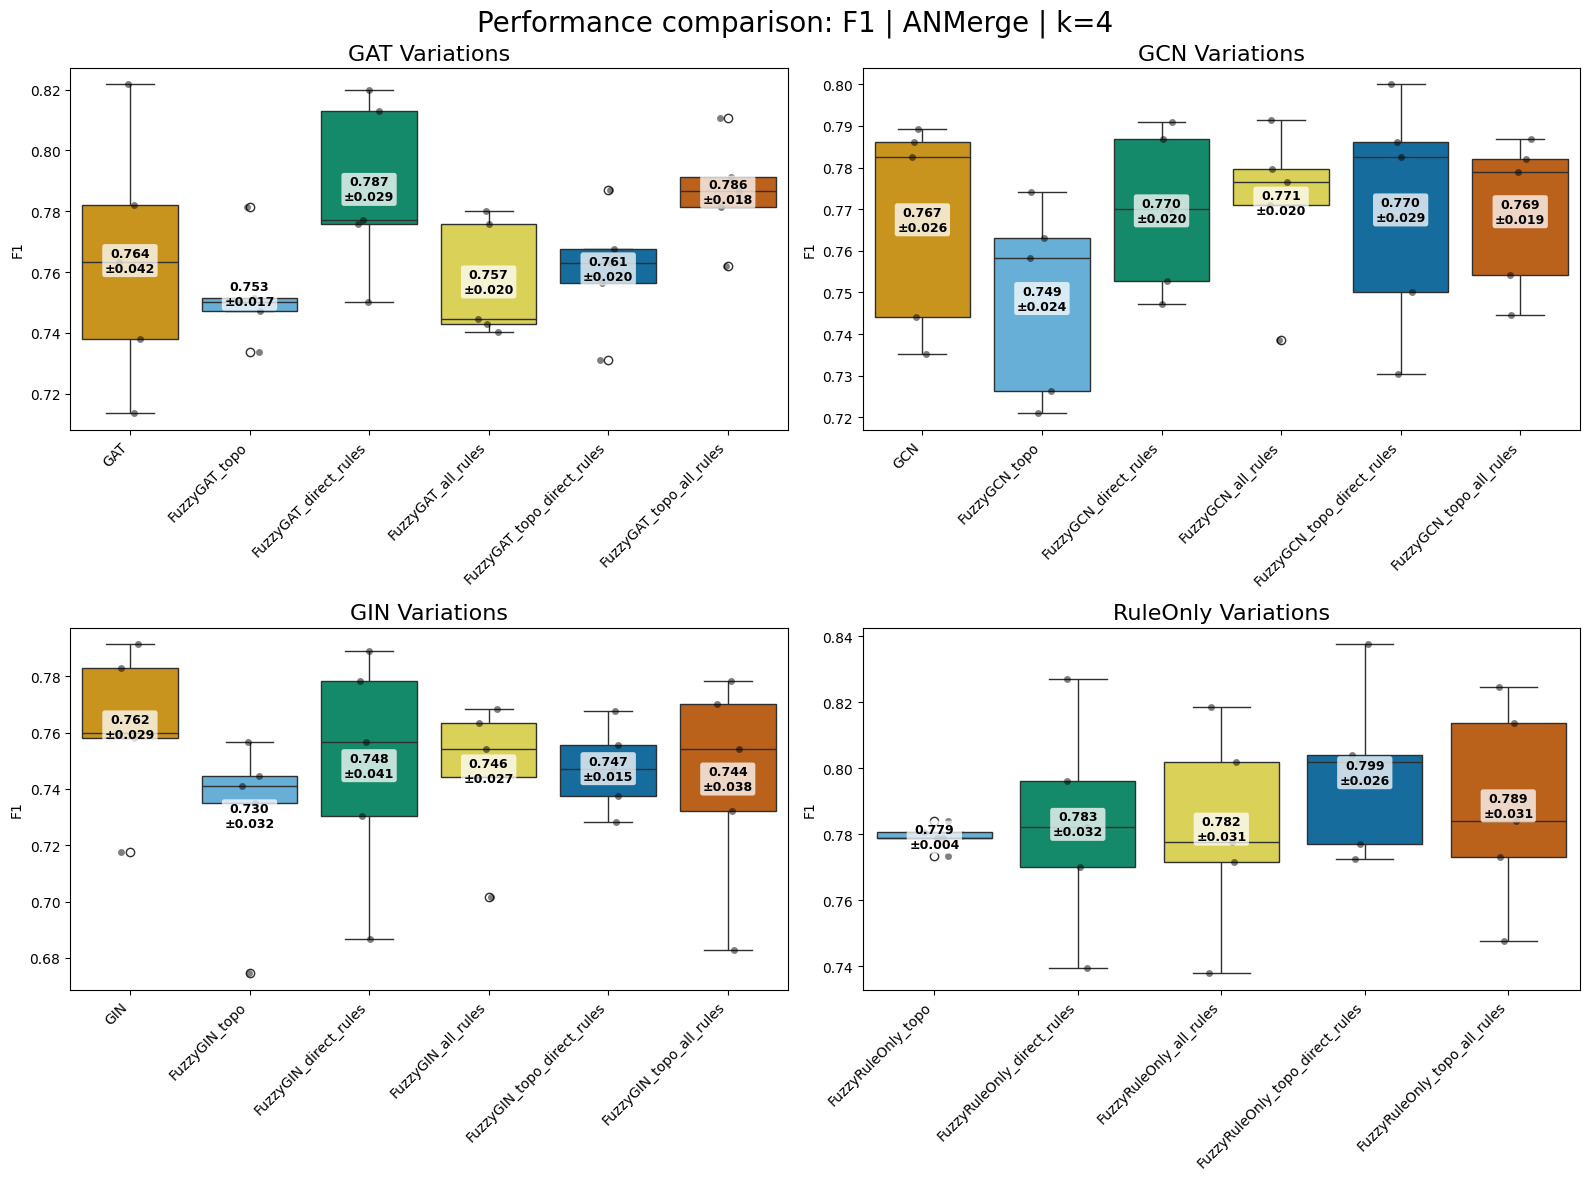

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of tic

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_backbones_ANMerge_k4_f1_macro.png


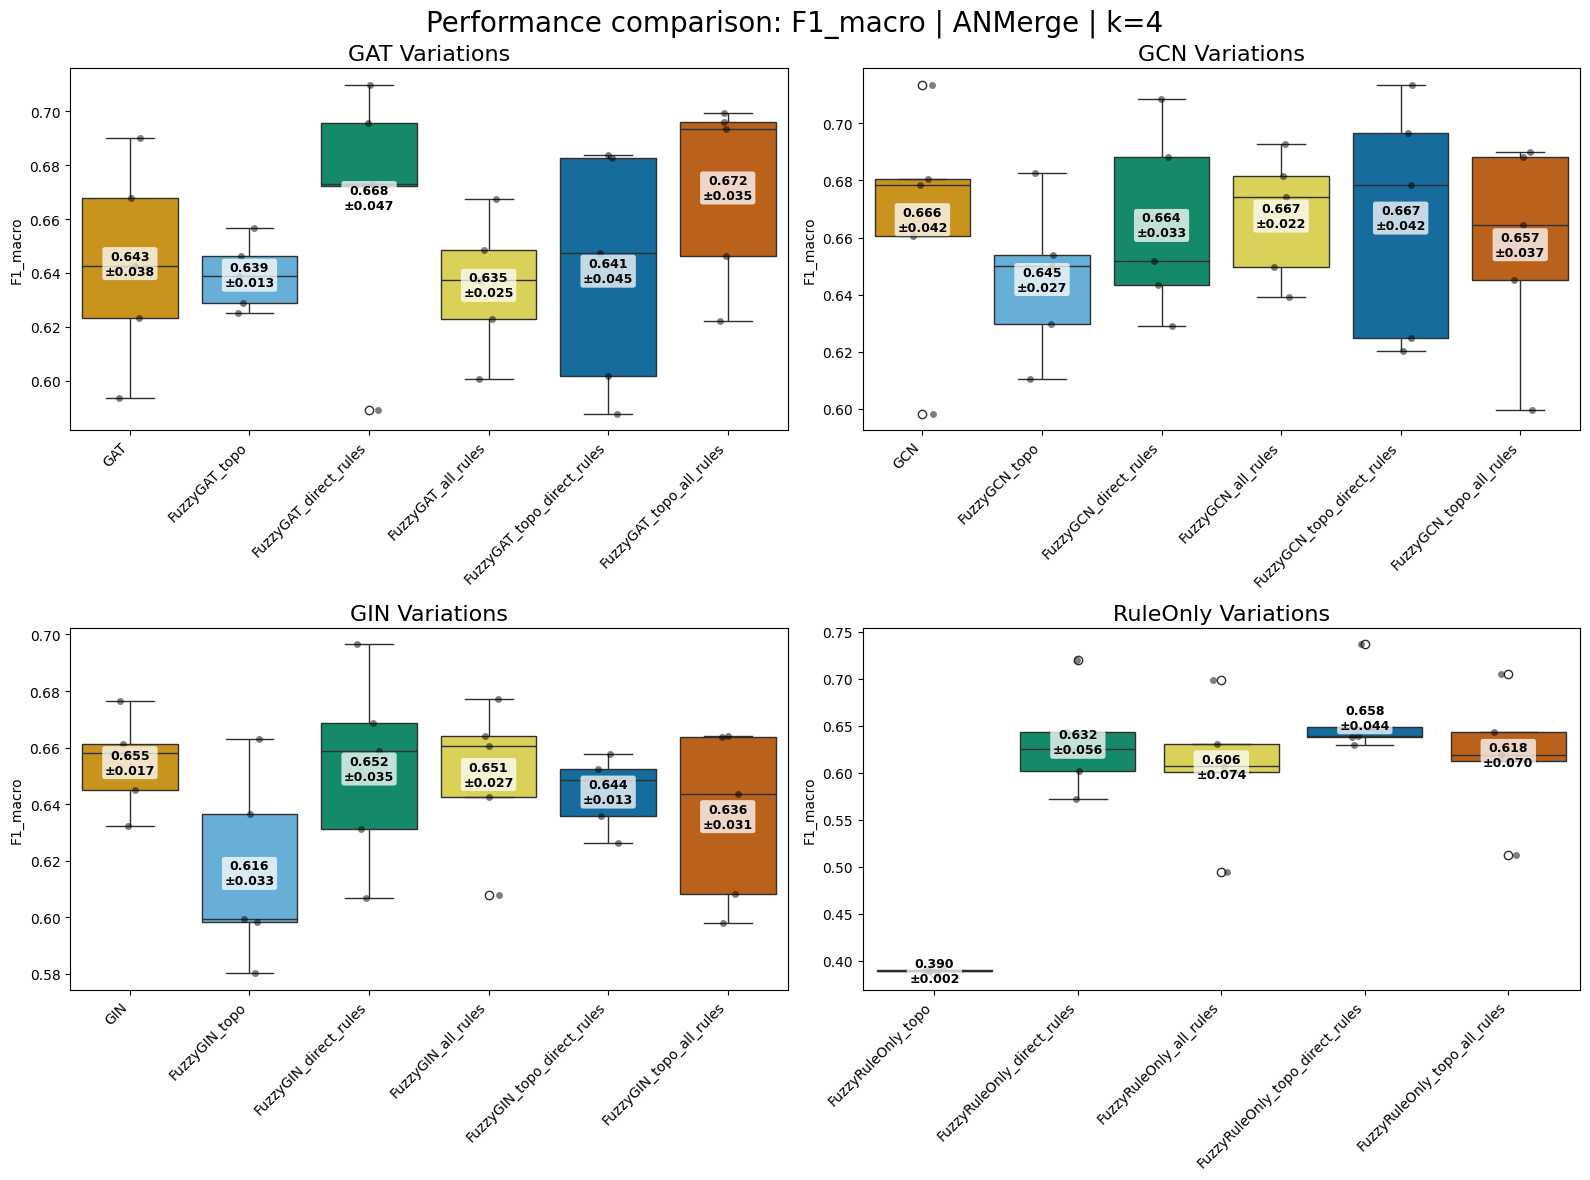

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of tic

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_backbones_ANMerge_k4_f1_weighted.png


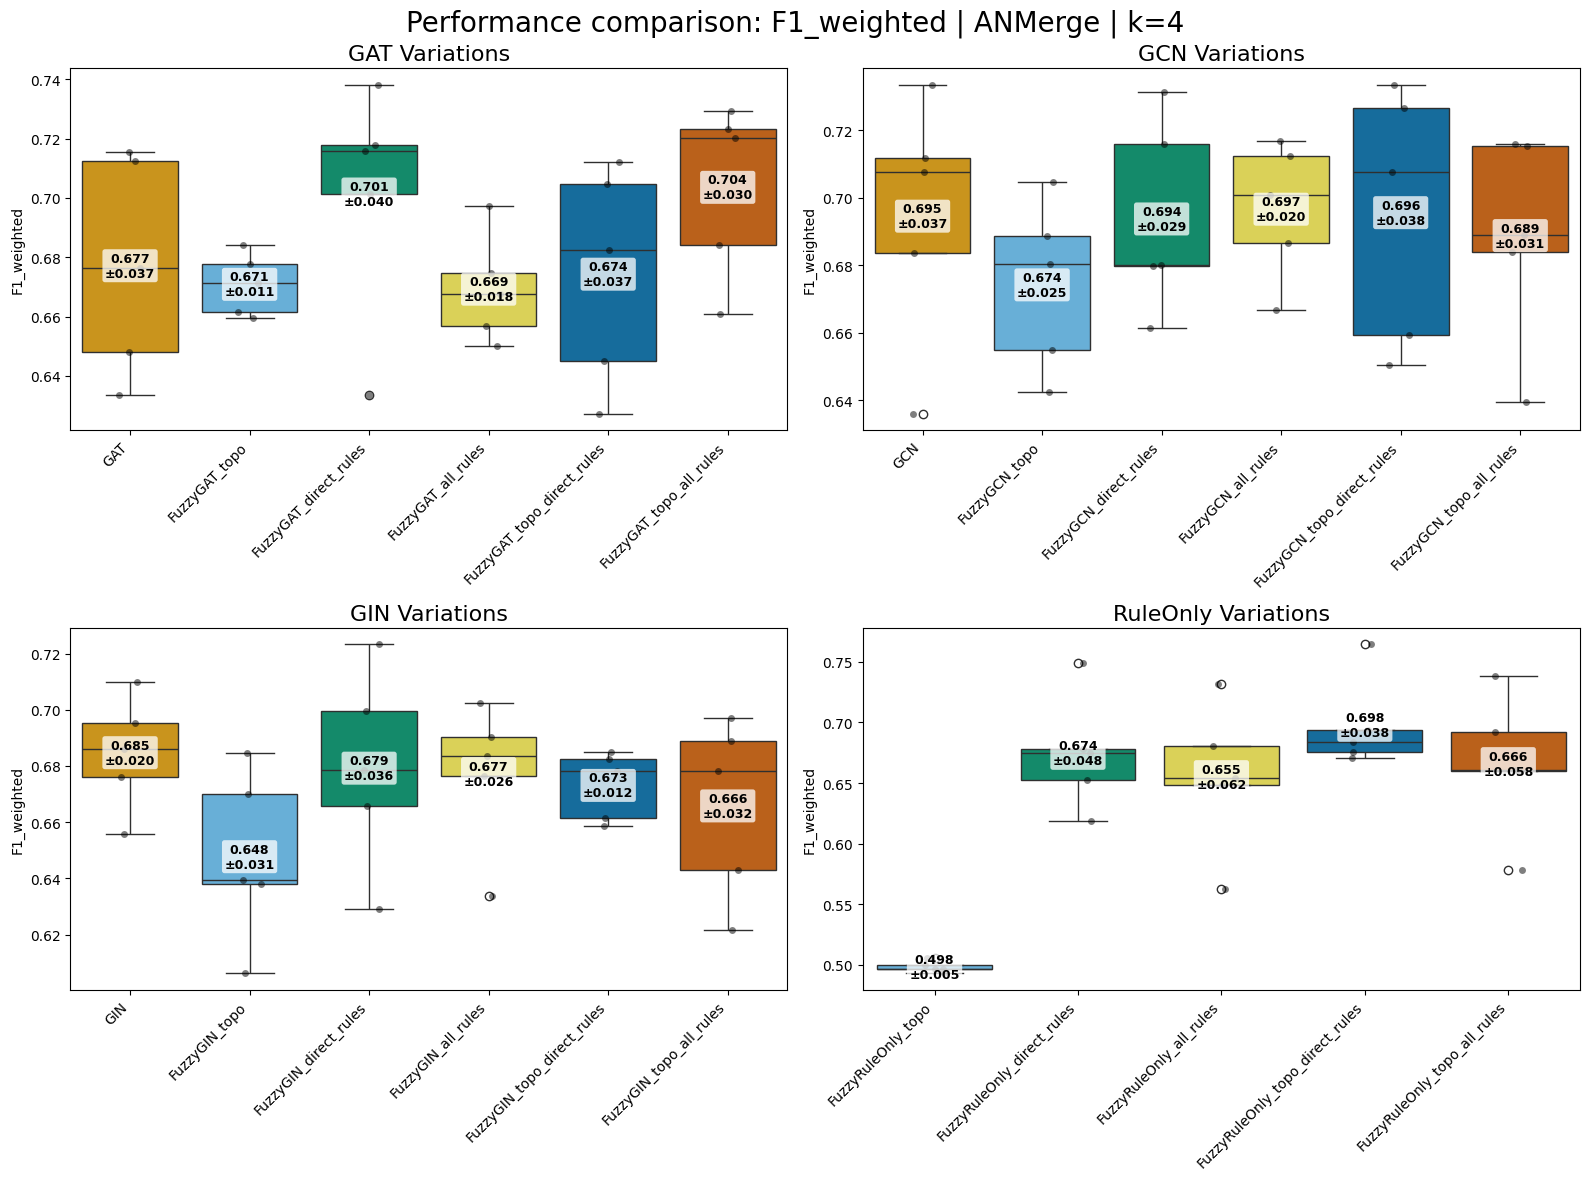

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of tic

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_backbones_ANMerge_k4_auroc.png


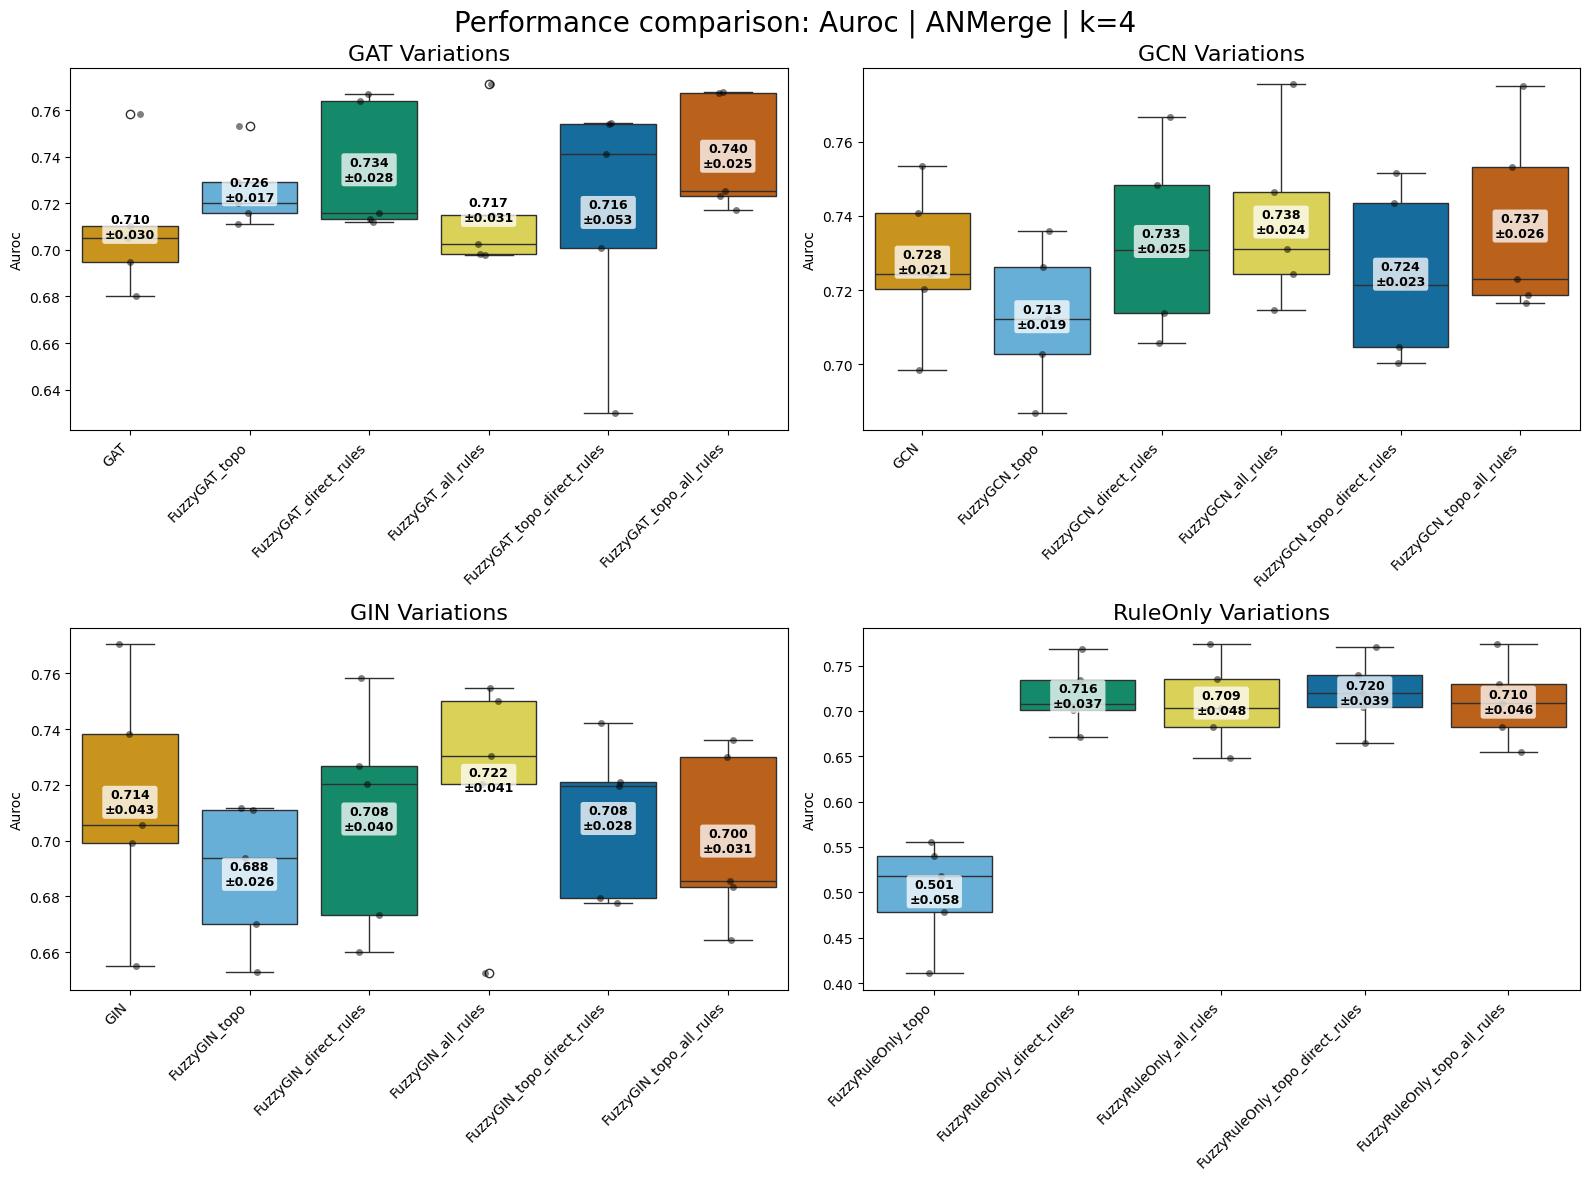

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_12048/3077437772.py:133: UserWarning: set_ticklabels() should only be used with a fixed number of tic

Saved plot to: ../nesy_gnn/results/explain/AD_KG/metric_plots/all_backbones_ANMerge_k4_auprc.png


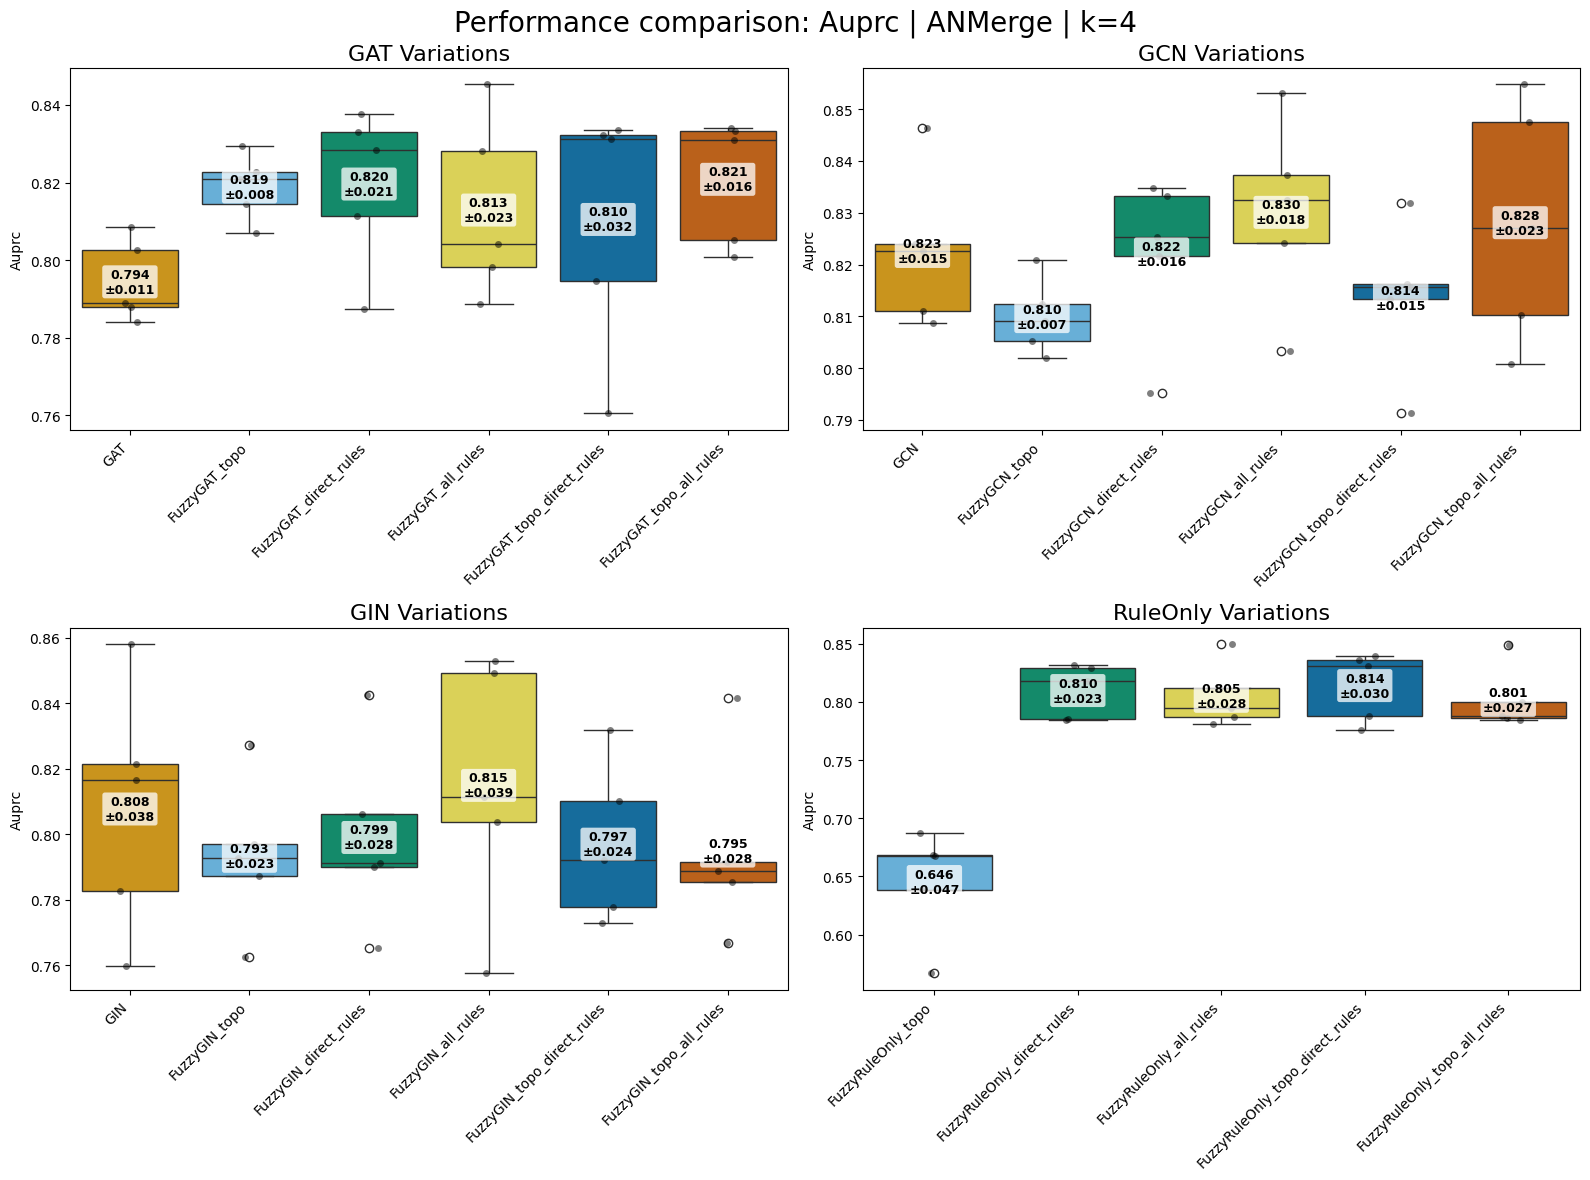

In [5]:
root_dir = "../nesy_gnn/results/explain/AD_KG"
save_plot = "../nesy_gnn/results/explain/AD_KG/metric_plots"
df_metrics = parse_cv_metrics(root_dir)
df = df_metrics.melt(
    id_vars=[
        "dataset",
        "k",
        "model",
        "fold"
    ],
    value_vars=['accuracy', 'balanced_accuracy', 'f1', 'f1_macro',
       'f1_weighted', 'auroc', 'auprc'],
    var_name="metric",
    value_name="score",
)
dataset = 'ANMerge'
for metric in ['accuracy', 'balanced_accuracy', 'f1', 'f1_macro',
       'f1_weighted', 'auroc', 'auprc']:
    boxplot_all_backbones_subplots(df=df, 
                                   metric_name=metric, 
                                   dataset=dataset,
                                   k=4, 
                                   output_dir=save_plot)